# Building Heating Load: TensorBoard Experiment Tracking
**Machine Learning Operations — Allen Febi Mariaantony Alphonsa**

This is my original regression project based on the experiment-tracking workflow in TensorBoard Lab 4. I use the UCI Energy Efficiency dataset instead of Fashion-MNIST. I compare eight neural networks, select one using validation MAE, and evaluate it once on a separate test set.

The observations are simulated building designs. I group by building geometry before splitting, so orientation and glazing variants of a geometry cannot cross the split boundaries. The data source and license are in `data/README.md`.

## 1. Inspect the data
X1–X5 describe geometry; X6 is orientation; X7 is glazing area; X8 is glazing distribution. Y1 is the heating-load target. Y2 (cooling load) is excluded from inputs to avoid using another outcome as a predictor.

In [1]:
import pandas as pd
from IPython.display import display, Image
from experiment import ROOT, run
frame = pd.read_excel(ROOT / 'data/ENB2012_data.xlsx').dropna(how='all')
print('Data shape:', frame.shape)
print('Missing values:', int(frame.isna().sum().sum()))
print('Unique building geometries:', frame.X1.nunique())
display(frame.head())

Data shape: (768, 10)
Missing values: 0
Unique building geometries: 12


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


## 2. Run the experiment
I fit numeric scaling on training rows only and one-hot encode categorical features with their documented possible values. I scale the target using only the training mean and standard deviation. The search varies hidden-layer width (32/64), dropout (0/0.1), and Adam learning rate (0.001/0.01). Each run has a maximum of 150 epochs with early stopping after 20 epochs without validation MAE improvement. The best weights are restored.

TensorBoard records epoch curves and an HParams session for each run. Final validation MAE is logged in the original target units. The selected checkpoint is evaluated on the test set after the search. Re-running requires moving the existing `logs/` folder aside to keep experiment evidence separate.

In [2]:
summary = run()

/usr/local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{"run": "trial-00", "units": 32, "dropout": 0.0, "learning_rate": 0.001, "epochs": 26, "best_epoch": 6, "validation_mae": 3.433170690536499, "validation_rmse": 4.509319800559421, "validation_r2": 0.5751673658101377}


/usr/local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{"run": "trial-01", "units": 32, "dropout": 0.0, "learning_rate": 0.01, "epochs": 21, "best_epoch": 1, "validation_mae": 3.0016004261374474, "validation_rmse": 3.616639620781295, "validation_r2": 0.7267209943388104}


/usr/local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{"run": "trial-02", "units": 32, "dropout": 0.1, "learning_rate": 0.001, "epochs": 23, "best_epoch": 3, "validation_mae": 2.6918093207478524, "validation_rmse": 3.9041653652166803, "validation_r2": 0.6815419685880357}


... (7 outputs left out)

{"run": "trial-06", "units": 64, "dropout": 0.1, "learning_rate": 0.001, "epochs": 23, "best_epoch": 3, "validation_mae": 2.6964435827732087, "validation_rmse": 3.2435539028335727, "validation_r2": 0.780194762483075}


/usr/local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{"run": "trial-07", "units": 64, "dropout": 0.1, "learning_rate": 0.01, "epochs": 21, "best_epoch": 1, "validation_mae": 4.846698063910008, "validation_rmse": 5.197766228919263, "validation_r2": 0.43554505320212544}


{
  "selected": {
    "run": "trial-02",
    "units": 32,
    "dropout": 0.1,
    "learning_rate": 0.001,
    "epochs": 23,
    "best_epoch": 3,
    "validation_mae": 2.6918093207478524,
    "validation_rmse": 3.9041653652166803,
    "validation_r2": 0.6815419685880357
  },
  "test": {
    "mae": 2.840750702619553,
    "rmse": 4.0029044805206775,
    "r2": 0.7628777434761902
  },
  "mean_baseline_test": {
    "mae": 8.10460974702381,
    "rmse": 8.652466819348632,
    "r2": -0.10790303104116972
  },
  "split_rows": {
    "train": 448,
    "validation": 128,
    "test": 192
  },
  "split_geometries": {
    "train": [
      0.64,
      0.69,
      0.71,
      0.74,
      0.76,
      0.79,
      0.98
    ],
    "validation": [
      0.66,
      0.82
    ],
    "test": [
      0.62,
      0.86,
      0.9
    ]
  },
  "seed": 42,
  "data_sha256": "0089fcffc1415e41e2ff63730cca5280efe54fc43d722dfde1b0aaa808e35dc4",
  "environment": {
    "python": "3.11.18",
    "platform": "Linux-5.15.0-198-

## 3. Compare validation results
The ranking uses validation data only. Lower MAE is better.

In [3]:
trials = pd.read_csv(ROOT / 'results/trials.csv')
display(trials.sort_values('validation_mae').round(4))

,run,units,dropout,learning_rate,epochs,best_epoch,validation_mae,validation_rmse,validation_r2
2,trial-02,32,0.1,0.001,23,3,2.6918,3.9042,0.6815
6,trial-06,64,0.1,0.001,23,3,2.6964,3.2436,0.7802
4,trial-04,64,0.0,0.001,23,3,2.9872,3.7870,0.7004
1,trial-01,32,0.0,0.010,21,1,3.0016,3.6166,0.7267
3,trial-03,32,0.1,0.010,21,1,3.3363,4.0004,0.6657
0,trial-00,32,0.0,0.001,26,6,3.4332,4.5093,0.5752
7,trial-07,64,0.1,0.010,21,1,4.8467,5.1978,0.4355
5,trial-05,64,0.0,0.010,21,1,4.8862,5.4690,0.3751


## 4. Evaluate unseen geometries
I compare the selected model with a baseline that always predicts the training-set mean.

,Selected neural network,Training-mean baseline
mae,2.8408,8.1046
rmse,4.0029,8.6525
r2,0.7629,-0.1079


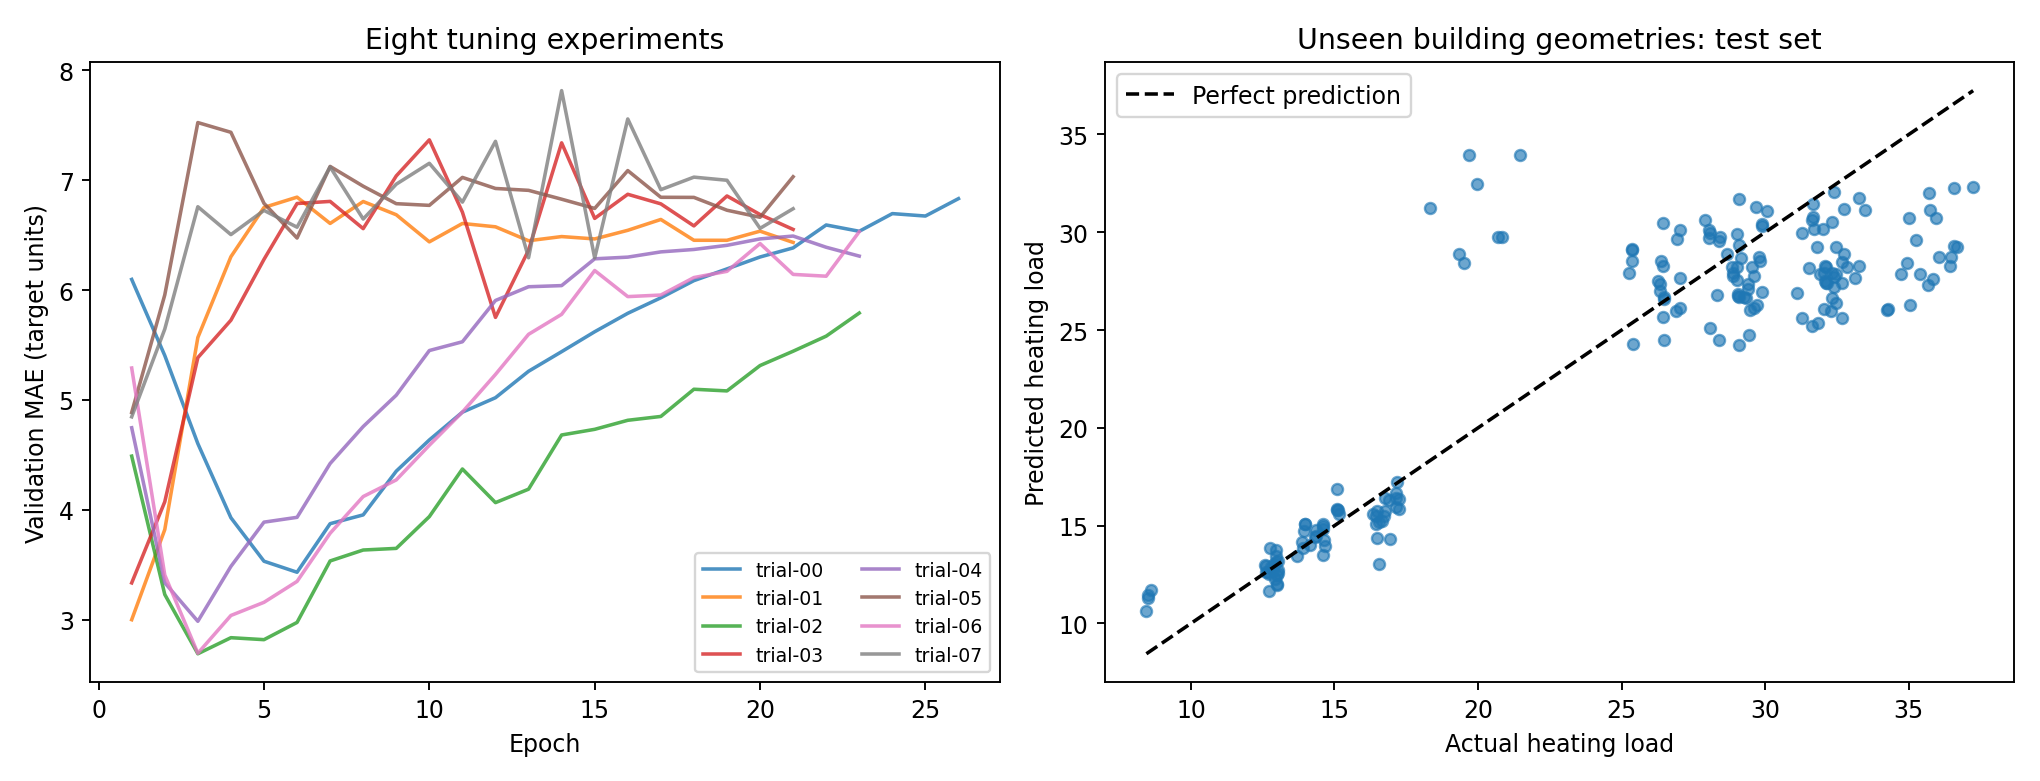

In [4]:
display(pd.DataFrame({'Selected neural network': summary['test'], 'Training-mean baseline': summary['mean_baseline_test']}).round(4))
display(Image(filename=str(ROOT / 'results/evaluation.png')))

## 5. Inspect TensorBoard
Run `tensorboard --logdir logs --host 127.0.0.1 --port 6006` from this folder, open http://localhost:6006, and select **HParams**. Compare the eight runs in the table and parallel-coordinates views. The Scalars/Time Series view shows the training and validation curves.

## 6. Limits
There are only 12 simulated geometries, so a single grouped split is an uncertain estimate. This experiment does not establish accuracy for measured buildings or climates outside this dataset. The fixed seed improves repeatability, but hardware and library changes can affect numeric results. Cross-validation across geometries and repeated training seeds would be useful follow-up work. The README discusses the actual measured result.

## My observations from the completed run
I selected trial-02 (32 units, dropout 0.1, learning rate 0.001) using validation MAE 2.6918. On the 192 test rows from three unseen geometries, MAE was 2.8408, RMSE was 4.0029, and R² was 0.7629. The training-mean baseline had MAE 8.1046.

The selected model restored epoch 3 after stopping at epoch 23. Validation error increased later in training, so keeping the final weights would have been a poor choice. Trial-06 was almost tied on validation MAE, and had a better validation RMSE; I followed the MAE rule rather than changing the selection metric. The prediction plot shows remaining errors, especially for high-load designs. This is a small simulation dataset, so these results are limited to this grouped split.

In [5]:
import subprocess, sys
check = subprocess.run([sys.executable, 'verify.py'], capture_output=True, text=True)
print(check.stdout)
if check.returncode:
    print(check.stderr)
    check.check_returncode()

PASS: all 768 rows assigned once; 12 geometries isolated across splits
PASS: preprocessing and target scaling fitted using training rows
PASS: eight trials; selection uses minimum validation MAE
PASS: saved model reproduces recorded predictions and test metrics
PASS: eight TensorBoard HParams sessions contain the recorded validation metrics
All verification checks passed.

